# T1 Vision por computador Jose Quimi

Este archivo es para realizar los procesos paso a paso, posteriormente se arma un archivo main.py que ejecuta el codigo compelto por si solo

In [2]:
# imports
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [ ]:
# imgs paths
img_path = os.path.join("..", "imgs")
# print(os.path.join(img_path, "img1.jpg"))
img1, img2, img3, img4 = [cv2.imread(os.path.join(img_path, f"img{i}.jpg")) for i in range(1, 5)]
N, M = img1.shape[:2] # eliminando el canal de color

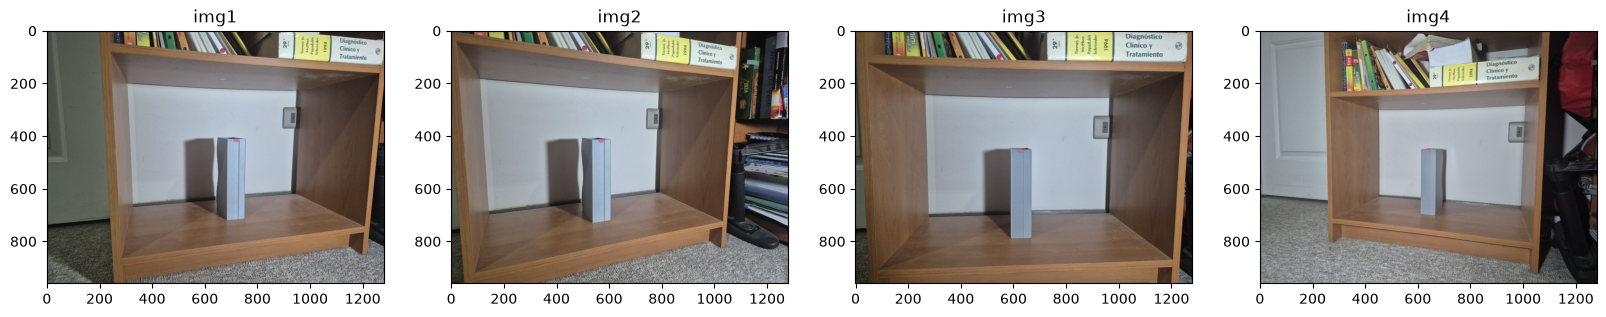

Shape = (960, 1280, 3)


In [4]:
# show imgs
fig, axs = plt.subplots(1, 4, figsize=(20, 10))
axs[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), cmap='gray')
axs[0].set_title('img1')

axs[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB), cmap='gray')
axs[1].set_title('img2')

axs[2].imshow(cv2.cvtColor(img3, cv2.COLOR_BGR2RGB), cmap='gray')
axs[2].set_title('img3')

axs[3].imshow(cv2.cvtColor(img4, cv2.COLOR_BGR2RGB), cmap='gray')
axs[3].set_title('img4')
plt.show()
print(f"Shape = {img1.shape}")

Utilizando la imagen 3 como imagen explicativa, los puntos se disponen en el siguiente orden, siendo el punto 1 el punto de origen, ademas se indica el punto objetivo.

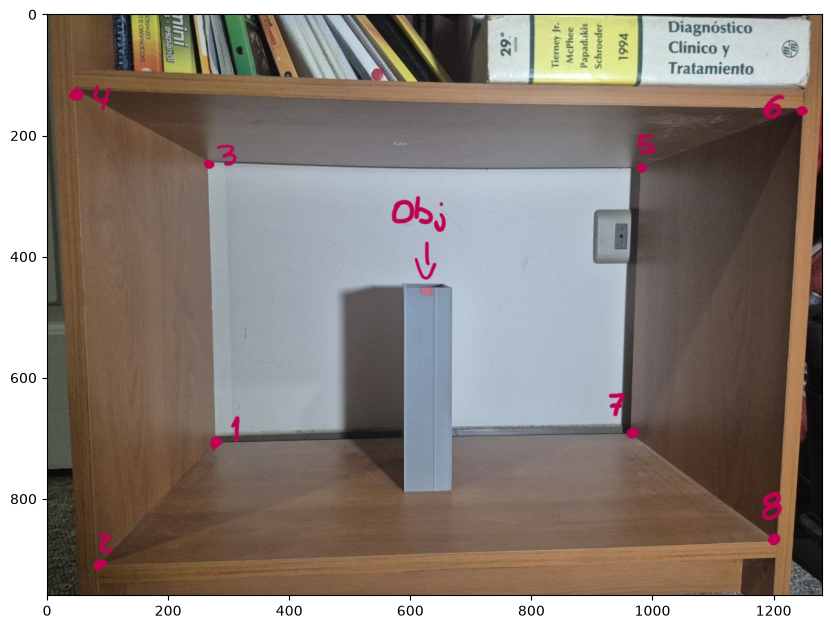

In [4]:
img_ej_path = os.path.join("..", "imgs/img_explicacion.jpg")
img_ej = cv2.imread(img_ej_path)
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img_ej, cv2.COLOR_BGR2RGB), cmap='gray')
plt.show()

In [ ]:
# definir M, los puntos reales con el punto 1 como el origen, todo en milimetros
M =np.array([
    [0.0,  0.0,   0.0,   0.0,   570.0, 570.0, 570.0, 570.0],
    [0.0,  294.0, 0.0,   294.0, 0.0,   294.0, 0.0,   294.0],
    [0.0,  0.0,   369.0, 369.0, 369.0, 369.0, 0.0,   0.0],
    [1.0,  1.0,   1.0,   1.0,   1.0,   1.0,   1.0,   1.0]
])

#### Obtener m1 de la imagen 1

In [ ]:
puntos_list = []

In [ ]:
def mouse_callback(event, x, y, flags, param):
    puntos_list, img = param
    if event == cv2.EVENT_LBUTTONDOWN:
        print(f"Clicked at: ({x}, {y})")
        puntos_list.append((x, y))
        
        cv2.circle(img, (x, y), 5, (0, 255, 0), -1)
        cv2.putText(img, f"{len(puntos_list)}", (x + 10, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    elif event == cv2.EVENT_RBUTTONDOWN:
        if puntos_list:
            punto_removido = puntos_list.pop()
            print(f"Punto removido {punto_removido}")
        img[:] = img.copy()
        
        for index, (px, py) in enumerate(puntos_list):
            cv2.circle(img, (px, py), 5, (0, 255, 0), -1)
            cv2.putText(img, f"{index + 1}", (px + 10, py - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
            
# Extraido de E02
def homography(X,H):
  Hinv  = np.linalg.inv(H)
  Xp    = np.zeros((N,M),np.uint8)

  m = np.ones((N*M,3))
  t = 0
  for i in range(N):
    for j in range(M):
      m[t,0:2] = [j,i]
      t = t+1

  mph = np.dot(Hinv,m.T)  # Transformation m to mp
  mp  = np.divide(mph[0:2,:],mph[2,:])
  mpf = np.trunc(mp).astype(int) #np.fix is deprecated

  ip = mpf[1,:]
  jp = mpf[0,:]
  ktj = np.logical_and(jp>=0,jp<M)
  kti = np.logical_and(ip>=0,ip<N)
  kt  = np.logical_and(kti,ktj)

  t = 0
  for i in range(N):
    for j in range(M):
      if kt[t]:
        Xp[i,j] = X[ip[t],jp[t]]
      t = t+1
  return Xp

def homography_matrix(m,mp):
  (x ,y ) = m
  (xp,yp) = mp
  n       = len(x)
  A       = np.zeros((2*n,9))
  for i in range(n):
    j = i*2
    A[j  ,:] = [x[i], y[i], 1,     0,     0, 0, -x[i]*xp[i], -y[i]*xp[i], -xp[i]]
    A[j+1,:] = [  0  ,   0  , 0, x[i], y[i], 1, -x[i]*yp[i], -y[i]*yp[i], -yp[i]]
  [U,S,V] = np.linalg.svd(A)
  h       = V[-1,:]
  H       = np.vstack([h[0:3], h[3:6], h[6:9]])
  return H
        

In [19]:
# levantar imagen y mostrarla en una ventana para obtener los puntos de las esquinas
display_img = img1.copy()
flag = True
cv2.namedWindow("Seleccionar puntos")
cv2.resizeWindow("Seleccionar puntos", img1.shape[1]-200, img1.shape[0]-200)
cv2.setMouseCallback("Seleccionar puntos", mouse_callback, param=(puntos_list, display_img))

while flag:
    cv2.imshow("Seleccionar puntos", display_img)
    key = cv2.waitKey(1) & 0xFF

    if key == ord('q'):
        flag = False
    elif key == ord('r'):
        puntos_list.clear()
        display_img = img1.copy()
        print("Puntos reiniciados")
cv2.destroyAllWindows()
print(f"Puntos seleccionados: {puntos_list}")


Clicked at: (330, 669)
Clicked at: (285, 865)
Clicked at: (305, 199)
Clicked at: (243, 82)
Clicked at: (966, 230)
Clicked at: (1264, 161)
Clicked at: (945, 618)
Clicked at: (1208, 743)
Puntos seleccionados: [(330, 669), (285, 865), (305, 199), (243, 82), (966, 230), (1264, 161), (945, 618), (1208, 743)]


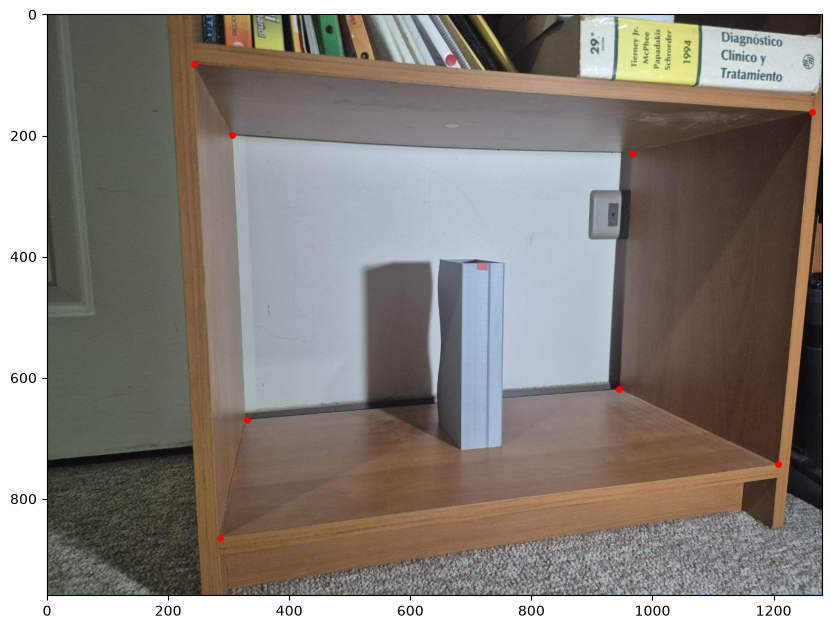

Los puntos que representan la caja son: [(330, 669), (285, 865), (305, 199), (243, 82), (966, 230), (1264, 161), (945, 618), (1208, 743)]


In [22]:
# Obtener m1 desde la imagen 1
# puntos = [(327, 670), (284, 863), (245, 80), (305, 198), (966, 225), (1262, 161), (946, 618), (1205, 743)]
# esto hay que cambiarlo por seleccion por medio de mouse en una ventana
x, y = zip(*puntos_list)

plt.figure(figsize=(10, 10))

plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), cmap='gray')
plt.scatter(x, y, color='red', s=15)
plt.show()
print(f"Los puntos que representan la caja son: {puntos_list}")

In [29]:
# Definir los vectores de m1
x_p = np.array([p[0] for p in puntos_list])
y_p = np.array([p[1] for p in puntos_list])
print(f"x_p = {x_p}")
print(f"y_p = {y_p}")

x_p = [ 330  285  305  243  966 1264  945 1208]
y_p = [669 865 199  82 230 161 618 743]
